<a href="https://colab.research.google.com/github/wlsldjtm9/p1-cnt/blob/main/p2_project_bank_marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# P2 프로젝트: 정기예금 가입

포르투갈 은행의 전화 마케팅 데이터를 이용하여 고객의 정기예금 가입 여부를 예측한다.

> **전화 통화를 시작하기 전에, 어떤 고객이 정기예금에 가입할 가능성이 높은지 예측할 수 있는가?**

제공된 코드를 출발점으로 이진 분류 프로젝트의 전체 흐름을 수행한다. AI의 도움을 받아도 되지만, **누수 판단, 평가 지표 해석, 결정 임곗값 선택, 최종 결론은 직접 판단한다.**

**코드 실행**

[(구글 코랩) P2 프로젝트: 정기예금 가입](https://colab.research.google.com/github/codingalzi/code-workout-ml/blob/master/p2_project_bank_marketing.ipynb)에서 코드를 실행할 수 있다.

**프로젝트 진행 원칙**

1. **최종 테스트셋은 모델과 임곗값 선택이 끝날 때까지 확인하지 않는다.**
2. **예측 시점에 알 수 없는 정보는 입력 특성에서 제외한다.**
3. **정확도 하나만으로 분류 모델을 판단하지 않는다.**
4. **결정 임곗값은 검증 데이터에서 선택하고 테스트 데이터에서 다시 조정하지 않는다.**
5. **AI는 도구로 활용하되 중요한 판단에는 자신의 근거를 남긴다.**

**환경설정**

In [ ]:
import sys
import sklearn
from packaging.version import Version

assert sys.version_info >= (3, 10)
assert Version(sklearn.__version__) >= Version("1.6.1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rc("font", size=12)
plt.rc("axes", labelsize=14, titlesize=14)
plt.rc("legend", fontsize=12)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)

## 1단계 — 문제 정의, 데이터 이해, EDA

### 문제를 데이터의 언어로 바꾼다

이번 프로젝트에서는 **현재 전화 통화가 시작되기 직전**을 예측 시점으로 정한다.

- **샘플**: 한 고객의 은행 마케팅 기록
- **타깃**: 정기예금 가입 여부 `y`
- **양성 클래스**: 가입 `yes`
- **음성 클래스**: 미가입 `no`
- **문제 유형**: 두 클래스 중 하나를 예측하는 **이진 분류**
- **예측 시점**: 현재 전화 통화를 시작하기 직전
- **분석 목적**: 가입 가능성이 높은 고객을 구분하고, 목적에 맞는 결정 임곗값을 선택한다.

예측 시점을 먼저 정해야 **어떤 변수를 실제 예측에 사용할 수 있는지** 판단할 수 있다.

### 프로젝트 기록 ① — 분석 설계

다음을 자신의 말로 작성한다.

- **분석 목적**: 고객이 정기예금 가입을 예측하기 위한 프로젝트
- **타깃과 양성 클래스**: 고객이 정기예금을 가입하고 있는지 상태를 나타내는 y와 양성 범주로는 가입을 나타내는 yes라고 할 수 있다.
- **이진 분류라고 판단한 이유**: 정기예금 가입 유무를 판단하는 것이기에 가입된지 아닌지를 구별하는 이진 분류라고 할 수 있다.
- **예측 시점**: 고객과 통화를 하기 직전 예측하는 프로젝트이다.
- **예측 결과를 실제로 어떻게 활용할 수 있는가?**: 고객의 성향과 정기예금 가입 유무를 판단하여 고객에게 맞춤형 금융상품 추천할 수 있다. 또 고객이 관심을 가질만한 광고를 선별하여 발송할 수도 있다.

### 데이터를 불러와 구조를 확인한다

UCI Bank Marketing의 `bank-full.csv`에 해당하는 데이터를 사용한다.  
45,211개의 사례와 16개의 입력 특성이 포함된 버전이다.

In [ ]:
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip"

with urlopen(url) as response:
    zip_data = BytesIO(response.read())

with ZipFile(zip_data) as z:
    df = pd.read_csv(
        z.open("bank-full.csv"),
        sep=";"
    )

df["y"] = (df["y"] == "yes").astype(int)

print("데이터 크기:", df.shape)
df.head()

데이터 크기: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0


필요한 열이 모두 들어왔는지 확인한다.

In [ ]:
required_cols = {
    "age", "job", "marital", "education", "default",
    "balance", "housing", "loan", "contact", "day",
    "month", "duration", "campaign", "pdays",
    "previous", "poutcome", "y"
}

missing_cols = sorted(required_cols - set(df.columns))

if missing_cols:
    raise ValueError(f"필요한 열이 없습니다: {missing_cols}")

print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [ ]:
df.info()

`unknown`은 이 데이터에서 하나의 범주로 기록되어 있다.  
이번 프로젝트에서는 임의로 다른 값으로 바꾸지 않고 **하나의 범주로 그대로 사용**한다.

### 최종 테스트셋을 먼저 보존한다

전체 데이터의 20%를 **최종 테스트셋**으로 분리한다.

타깃 비율이 크게 달라지지 않도록 `stratify`를 사용한다.  
테스트셋의 타깃 분포와 모델 성능은 최종 평가 전까지 확인하지 않는다.

In [ ]:
from sklearn.model_selection import train_test_split

dev_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["y"],
    random_state=42
)

print("개발 데이터:", dev_df.shape)
print("최종 테스트 데이터:", test_df.shape)

개발 데이터: (36168, 17)
최종 테스트 데이터: (9043, 17)


### 개발 데이터에서 클래스 비율을 확인한다

정확도만으로 모델을 평가해도 되는지 판단하려면 먼저 클래스 비율을 확인해야 한다.

In [ ]:
target_summary = pd.DataFrame({
    "count": dev_df["y"].value_counts().sort_index(),
    "rate": dev_df["y"].value_counts(normalize=True).sort_index()
})

target_summary.index = ["no", "yes"]
target_summary

,count,rate
no,31937,0.883018
yes,4231,0.116982


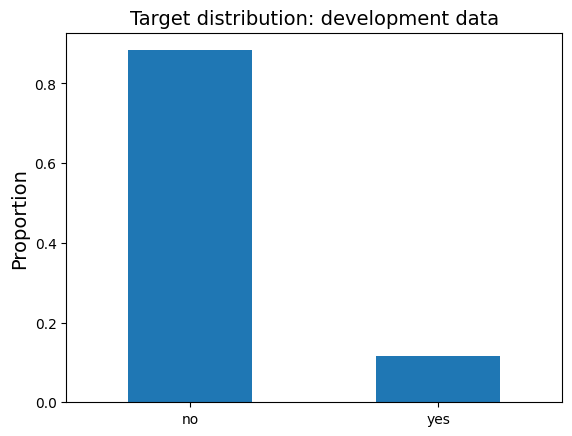

In [ ]:
target_summary["rate"].plot(kind="bar")

plt.ylabel("Proportion")
plt.title("Target distribution: development data")
plt.xticks(rotation=0)
plt.show()

가입 고객이 전체에서 소수라면, 대부분을 `no`로 예측하는 모델도 높은 정확도를 얻을 수 있다.

따라서 이번 프로젝트에서는 **정확도뿐 아니라 정밀도, 재현율, ROC-AUC를 함께 본다.**

### 모델링 전에 데이터 누수를 점검한다

`duration`은 **마지막 전화 통화가 몇 초 동안 지속되었는지**를 나타낸다.

이번 프로젝트의 예측 시점은 **전화 통화를 시작하기 직전**이다.  
따라서 그 시점에는 통화가 얼마나 오래 지속될지 알 수 없다.

> **예측 시점에 알 수 없는 `duration`을 입력 특성으로 사용하면 데이터 누수가 발생한다.**

`duration`은 가입 여부와 강한 관련이 있을 수 있으므로 모델 성능을 크게 높일 수 있다. 하지만 실제 예측에서는 사용할 수 없기 때문에 최종 모델에서는 제외한다.

In [ ]:
# 개발 데이터에서만 duration과 가입 여부의 관계를 확인한다.
dev_df.groupby("y")["duration"].agg(
    ["count", "mean", "median"]
).rename(index={0: "no", 1: "yes"})

,count,mean,median
y,,,
no,31937,221.085982,164.0
yes,4231,540.972820,426.0


`duration`이 가입 여부를 잘 구분한다고 해서 좋은 입력 변수라는 뜻은 아니다.

중요한 질문은 다음이다.

> **모델이 실제 예측을 하는 순간에 이 정보를 알 수 있는가?**

이번 프로젝트에서는 `duration`을 **누수 확인용으로만 살펴보고 실제 모델의 입력에서는 제외한다.**

### 프로젝트 기록 ② — 입력 변수와 데이터 누수

다음을 작성한다.

- `duration`이 가입 여부 예측에 유용해 보일 수 있는 이유: `duration`이 길다는 것은 고객과 은행원이 긴 통화를 했다는 것을 의미한다. 그러면 고객은 은행과 관련된 일로 은행원과 통화를 했을 확률이 많다. 정기예금뿐만 아니라 대출이나 다른 금융상품에 대해서 이야기를 했다는 말인데 즉 통화를 짧게 한 고객 보다는 길게 통화한 고객이 정기예금을 했을 확률이 더 높다고 생각할 수 있어 가입 여부 예측에 유용해 보인다.
- 그래도 `duration`을 제외해야 하는 이유: 모델 예측을 어느 시점에 하는지가 중요하다 모델 예측 시점이 통화를 하기 직전이므로 고객과 통화 시간을 알 수 없다. 그래서 모델이 알 수 없는 데이터를 사용하여 학습하면 정확도가 높게 나올 수 있어도 실제 새로운 데이터를 사용했을 때 잘못 예측할 수 있기 때문이다.
- **예측 시점**을 다르게 정의하면 `duration`을 사용할 수도 있는가? 그 이유는?: 예측 시점을 통화를 하고 난 후로 정의하면 `duration`을 사용할 수 있다고 생각한다. 오히려 사용하지 않을 이유가 없다. 예측시점이 통화 직전일 때는 모델이 알 수 없는 데이터 여서 제외를 시켰다면 통화가 끝난 후 라면 모델이 충분히 알 수 있는 데이터이기 때문이다.
- 다른 변수들도 예측 시점에 사용할 수 있는지 어떻게 확인해야 하는가?: 예측 시점을 따져봐서 미래에 발생하는 데이터라면 사용하지 못한다. 또 정답을 이용해서 만들어진 데이터 인지도 확인해야한다. 결과나 정답을 직접적으로 반영하는 데이터라면 누수가 발생 할 수 있다.

### 개발 데이터만 탐색한다

최종 테스트셋은 아직 사용하지 않는다.

먼저 직업별 가입률을 확인한다.

In [ ]:
job_rate = (
    dev_df.groupby("job", dropna=False)["y"]
          .agg(["mean", "count"])
          .sort_values("mean", ascending=False)
)

job_rate

,mean,count
job,,
student,0.288918,758
retired,0.229581,1812
unemployed,0.154297,1024
management,0.138597,7511
admin.,0.122917,4141
unknown,0.119658,234
self-employed,0.114240,1243
technician,0.109262,6068
services,0.089008,3348


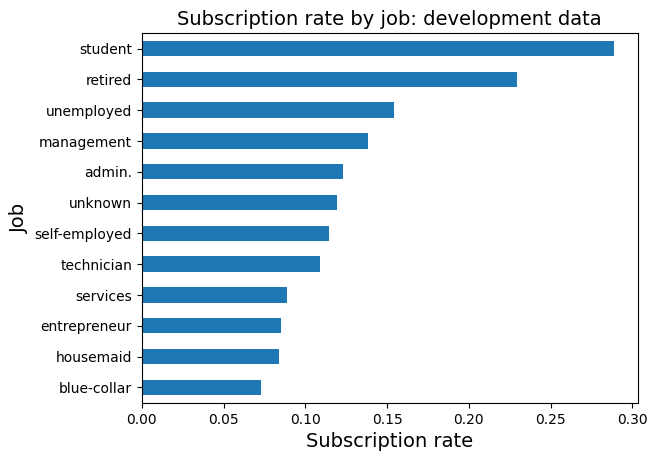

In [ ]:
job_rate["mean"].sort_values().plot(kind="barh")

plt.xlabel("Subscription rate")
plt.ylabel("Job")
plt.title("Subscription rate by job: development data")
plt.show()

이전 마케팅 캠페인의 결과(`poutcome`)에 따라서도 가입률이 다른지 확인한다.

In [ ]:
poutcome_rate = (
    dev_df.groupby("poutcome", dropna=False)["y"]
          .agg(["mean", "count"])
          .sort_values("mean", ascending=False)
)

poutcome_rate

,mean,count
poutcome,,
success,0.646473,1205
other,0.164983,1485
failure,0.122911,3889
unknown,0.092230,29589


### 나만의 EDA 질문 하나를 만든다

다음 변수 중 하나 이상을 사용하여 질문을 만든다.

`age`, `education`, `balance`, `housing`, `loan`, `month`, `campaign`, `pdays`, `previous`

예:

- 교육 수준에 따라 가입률이 다른가?
- 주택 대출 보유 여부와 가입률은 관련이 있는가?
- 이전 접촉 횟수와 가입 여부는 어떤 관계가 있는가?

**나의 질문**

> 작성: 계좌 잔액(`balance`)이 높은 고객일수록 정기예금 가입률이 높은가?

        balance_group  subscription_rate  customer_count
0   (-8019.001, 23.0]           6.822237            7285
1       (23.0, 275.0]          10.081819            7211
2      (275.0, 704.0]          11.721459            7209
3     (704.0, 1859.0]          13.483612            7231
4  (1859.0, 102127.0]          16.413164            7232


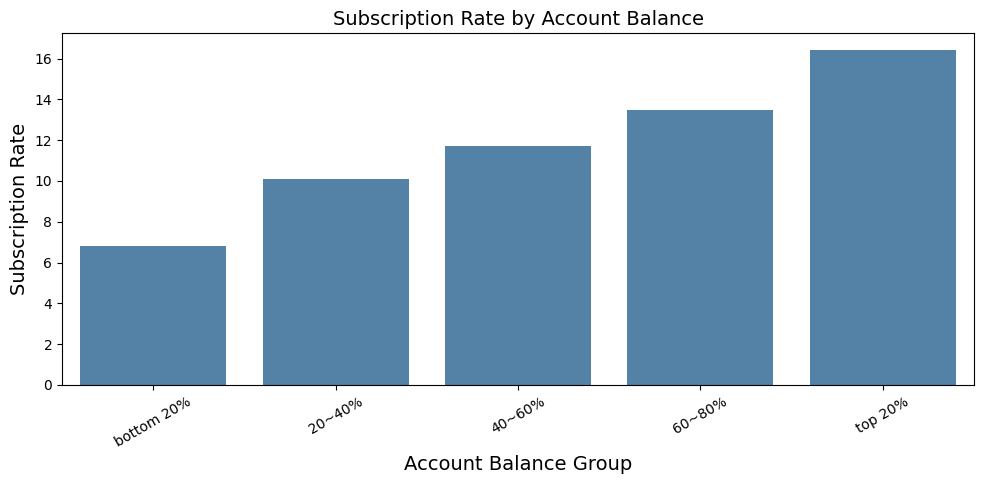

In [ ]:
# TODO
# 위에서 정한 EDA 질문을 확인하는 코드를 작성한다.
#

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

eda_df = dev_df[['balance','y']].copy()

eda_df['balance_group'] = pd.qcut(
    eda_df['balance'],
    q=5,
    duplicates='drop'
)

result = eda_df.groupby('balance_group', observed=True).agg(
    subscription_rate=('y', 'mean'),
    customer_count=('y','count')
).reset_index()

result['subscription_rate']*=100

result['balance_group'] = result['balance_group'].astype(str)
print(result)

labels = [
    'bottom 20%',
    '20~40%',
    '40~60%',
    '60~80%',
    'top 20%'
]

plt.figure(figsize=(10,5))

sns.barplot(
    data=result,
    x='balance_group',
    y='subscription_rate',
    color='steelblue'
)

plt.xticks(
    ticks=range(5),
    labels=labels
)

plt.title('Subscription Rate by Account Balance')
plt.xlabel('Account Balance Group')
plt.ylabel('Subscription Rate')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### AI 체크포인트 ① — EDA

AI에게 자신의 질문과 사용할 변수를 알려주고 분석 코드를 제안받아도 된다.

실행 전에는 다음을 직접 확인한다.

- **개발 데이터만 사용하는가?**
- 질문에 맞는 변수와 그래프인가?
- 범주형과 수치형의 의미를 잘못 해석하지 않았는가?
- 관찰된 관계를 인과관계로 단정하지 않았는가?

### 프로젝트 기록 ③ — EDA에서 발견한 것

세 가지를 기록한다.

- **발견 1**: 계좌잔액이 높은 구간일수록 가입률이 높게 나왔다. 상위 20%와 하위 20%는 2배 이상 차이가 난다. / 잔액수준 차이로 가입률 차이가 있다는 것을 보여주며 정기예금 가입 여부를 예측하는데 유용한 변수이다.
- **발견 2**: 계좌 잔액이 상위 20%인 그룹도 가입하지 않은 고객이 훨씬 많다. 상위 20% 고객의 가입률은 약 16%정도 밖에 되지 않는다. / 계좌 잔액이 가입 여부를 예측하는데 도움이 될 수 있지만 잔액 하나만으로는 가입 여부를 정확하게 판단하기 어렵다. 다양한 변수들도 함께 고려한 필요가 있다.
- **발견 3**: 계좌 잔액의 구간별 범위에 큰차이가 나타났다. 쉬게 구분하기 위해 5구간으로 나눠 그래프를 그렸지만 한 구간 안에 고객별 잔액 차이가 클 수 있음을 확인 할 수 있었다. / 잔액의 원본 수치형 변수와 구간화한 변수를 각각 활용하여 예측 성능을 비교할 필요가 있다.

> 단순히 “가입률이 높다/낮다”에서 끝내지 말고, 어떤 정보가 예측에 유용할 수 있는지 설명한다.

### 입력 특성과 타깃을 확정한다

이번 프로젝트의 기본 분석에서는 `duration`을 제외하고 나머지 변수를 사용한다.

범주형 변수는 **원-핫 인코딩**, 수치형 변수는 **표준화**한다.

`education`에는 순서가 있어 보이지만 기본 분석에서는 `primary → secondary → tertiary` 사이의 간격이 동일하다고 가정하지 않기 위해 원-핫 인코딩한다.

`day` 역시 숫자로 저장되어 있지만 날짜의 순서를 나타내는 범주로 보고 원-핫 인코딩한다.

In [ ]:
target = "y"

exclude_cols = [
    target,
    "duration"  # 예측 시점 이후에 알 수 있는 누수 변수
]

feature_cols = [
    c for c in df.columns
    if c not in exclude_cols
]

categorical_cols = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "day",
    "month", "poutcome"
]

numeric_cols = [
    c for c in feature_cols
    if c not in categorical_cols
]

print("타깃:", target)
print("사용 특성:", feature_cols)
print("범주형:", categorical_cols)
print("수치형:", numeric_cols)

타깃: y
사용 특성: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']
범주형: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'day', 'month', 'poutcome']
수치형: ['age', 'balance', 'campaign', 'pdays', 'previous']


### 1단계 마무리 체크

다음을 설명할 수 있는지 확인한다.

- 예측 대상과 이진 분류 문제의 의미 : 이번 예측 대상은 정기예금 가입 여부를 나타내는 `y`이다. 예측 결과가 두가지 범위 중 하나이기에 이진 분류문제에 해당된다.
- 예측 시점이 중요한 이유 : 예측 시점은 모델이 언제 어떤 정보를 가지고 예측할 것인지 결정하는 기준이 되기에 중요하다.
- `duration`이 데이터 누수인 이유 : `duration`은 고객과의 마지막 통화시간을 의미한다. 전화하기 전에 가입여부를 예측하는 모델을 만들려고 하고 있다. 예측 시점또한 통화하기 직전이므로 `duration`을 사용한다면 데이터 누수가 발생한다.
- 양성 클래스 비율이 모델 평가에 미치는 영향 : 양성 클래스는 약 11%정도 있다. 클래스별 데이터 수에 차이가 많이 나 클래스 불균형이 있다. 이러한 경우 정확도가 높게 나와도 좋은 모델이라고 할 수 없다. 그래서 정확도 뿐만 아니라 정밀도, 재현율, AUC, ROC 등 여러 지표를 함께 확인하는 것이 좋다.
- 범주형 변수와 수치형 변수를 다르게 처리하는 이유 : 수치형 변수는 숫자의 크기와 차이의 의미를 가지지만 범주형 변수는 숫자의 크기가 의미를 가지지 않는다. 그래서 서로 다르게 처리해야한다. 예를 들어 학생을 1, 회사원을 2, 자영업자를 3 이라고 가정하면 단순 숫자로 바꾸면 모델이 자영업자가 학생보다 3배 크다는 식으로 잘못된 수치관계를 해석할 수 있어서 이다.

## 2단계 — 전처리, 모델 훈련, 검증과 임곗값 선택

### 개발 데이터를 학습용과 검증용으로 다시 나눈다

최종 테스트셋은 사용할 수 없으므로 개발 데이터 안에서 다시 나눈다.

- 전체 데이터의 약 60% → **학습용**
- 전체 데이터의 약 20% → **검증용**
- 앞에서 보존한 약 20% → **최종 테스트용**

학습용과 검증용도 양성 클래스 비율이 유지되도록 나눈다.

In [ ]:
train_df, val_df = train_test_split(
    dev_df,
    test_size=0.25,
    stratify=dev_df[target],
    random_state=42
)

X_train = train_df[feature_cols]
y_train = train_df[target]

X_val = val_df[feature_cols]
y_val = val_df[target]

print("학습용:", X_train.shape)
print("검증용:", X_val.shape)

학습용: (27126, 15)
검증용: (9042, 15)


### 전처리 과정을 하나의 파이프라인으로 묶는다

- **수치형 변수** → 결측치 처리 + 표준화
- **범주형 변수** → 결측치 처리 + 원-핫 인코딩

`Pipeline`을 사용하면 전처리도 학습 데이터에서만 `fit()`되고, 검증·테스트 데이터에는 이미 학습된 변환만 적용된다.

In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(numeric_features, categorical_features):
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features)
    ])

preprocess = build_preprocessor(
    numeric_cols,
    categorical_cols
)

### 기준선과 로지스틱 회귀를 비교한다

`DummyClassifier`는 입력 특성을 사용하지 않고 단순한 규칙으로 예측한다.  
이번에는 가장 많은 클래스인 `no`를 항상 예측하는 기준선으로 사용한다.

로지스틱 회귀가 기준선보다 어떤 점에서 나아지는지 확인한다.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

def make_pipeline(estimator, prep=preprocess):
    return Pipeline([
        ("prep", clone(prep)),
        ("model", estimator)
    ])

models = {
    "Baseline(most frequent)": make_pipeline(
        DummyClassifier(strategy="most_frequent")
    ),
    "LogisticRegression": make_pipeline(
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
}

### 같은 기준으로 검증한다

분류 모델은 하나의 숫자로만 평가하지 않는다.

- **Accuracy**: 전체에서 맞게 분류한 비율
- **Precision**: 가입한다고 예측한 고객 중 실제 가입한 비율
- **Recall**: 실제 가입 고객 중 모델이 찾아낸 비율
- **ROC-AUC**: 여러 임곗값에서 양성과 음성을 구분하는 능력을 요약한 값

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

def classification_scores(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "FP": fp,
        "FN": fn
    }

In [ ]:
validation_rows = []

for name, model in models.items():
    model.fit(X_train, y_train)

    proba = model.predict_proba(X_val)[:, 1]
    scores = classification_scores(
        y_val,
        proba,
        threshold=0.5
    )

    validation_rows.append({
        "Model": name,
        **scores
    })

validation_results = (
    pd.DataFrame(validation_rows)
      .set_index("Model")
)

validation_results

,Accuracy,Precision,Recall,ROC-AUC,FP,FN
Model,,,,,,
Baseline(most frequent),0.882990,0.000000,0.000000,0.50000,0,1058
LogisticRegression,0.895045,0.679868,0.194707,0.77748,97,852


### 정확도가 높은 것만으로 충분한가?

기준선은 대부분의 고객을 `no`라고 예측하기 때문에 정확도가 높게 보일 수 있다.

그러나 가입 고객을 전혀 찾아내지 못한다면 실제 마케팅 의사결정에는 도움이 되지 않는다.

**정확도, 정밀도, 재현율을 함께 해석한다.**

### 누수가 성능을 얼마나 왜곡하는지 확인한다

이번에는 경고를 위한 비교 실험으로 `duration`을 포함한 로지스틱 회귀를 한 번만 만들어 본다.

> 이 모델은 **실제 최종 후보가 아니다.**

검증 성능이 좋아지더라도, 예측 시점에 사용할 수 없는 정보를 이용했기 때문에 실제 문제를 해결하는 모델로 사용할 수 없다.

In [ ]:
leaky_feature_cols = feature_cols + ["duration"]

leaky_numeric_cols = numeric_cols + ["duration"]

leaky_preprocess = build_preprocessor(
    leaky_numeric_cols,
    categorical_cols
)

leaky_model = make_pipeline(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    prep=leaky_preprocess
)

leaky_model.fit(
    train_df[leaky_feature_cols],
    y_train
)

leaky_val_proba = leaky_model.predict_proba(
    val_df[leaky_feature_cols]
)[:, 1]

clean_model = models["LogisticRegression"]
clean_val_proba = clean_model.predict_proba(X_val)[:, 1]

leakage_comparison = pd.DataFrame({
    "No leakage": classification_scores(
        y_val, clean_val_proba, 0.5
    ),
    "With duration (leakage)": classification_scores(
        y_val, leaky_val_proba, 0.5
    )
}).T

leakage_comparison

,Accuracy,Precision,Recall,ROC-AUC,FP,FN
No leakage,0.895045,0.679868,0.194707,0.77748,97.0,852.0
With duration (leakage),0.902123,0.650960,0.352552,0.91101,200.0,685.0


### 프로젝트 기록 ④ — 모델과 누수 결과 해석

다음을 작성한다.

- 기준선의 정확도가 높게 보이는 이유: 모든 고객을 정기예금 미가입으로 예측했다. 그래서 실제 데이터에서 미가입 고객의 비율이 약 88%로 높기 때문에 정확도가 높게 나타났다. 따라서 정확도,정밀도,재현율 모두 확인할 필요가 있다.
- 로지스틱 회귀가 기준선보다 개선된 점: 로지스틱 회귀 모델의 정확도가 약89%로 기준선보다 약 1%정도 증가하였으며 기준선의 재현율은 0%였지만 로지스틱 회귀는 약19%이며, 정밀도도 약 67%, ROC-AUC는 약0.7로 나타났다. 실제 가입 고객을 어느정도 에측했다.
- `duration`을 포함했을 때 성능이 어떻게 달라졌는가?: 정확도가 올라갔으며 재현율과 ROC-AUC또한 증가했다. 하지만 정밀도가 감소했고 FP가 증가했다. 미가입 고객을 가입 고객으로 잘못 판단하는 경우가 크게 늘었음을 보여준다.
- 성능이 더 좋아졌더라도 누수 모델을 사용하면 안 되는 이유: 고객에게 전화하기 전에 정기예금 가입 가능성을 예측하는 것이프모 변수 `duration`은 전화를 하고난 후에 확인할 수 있는 정보이므로 이번 프로젝트에서는 사용할 수 없다. 검증 데이터에서 높은 성능을 보이더라도 실제 운영 환경에서 반영하기에는 어려움이 있다.

### 결정 임곗값에 따라 정밀도와 재현율이 달라진다

이제 **누수가 없는 로지스틱 회귀**만 사용한다.

기본 임곗값 `0.5`를 그대로 사용할 필요는 없다.  
검증 데이터에서 정밀도와 재현율의 변화를 확인한 뒤 프로젝트 목적에 맞는 값을 선택한다.

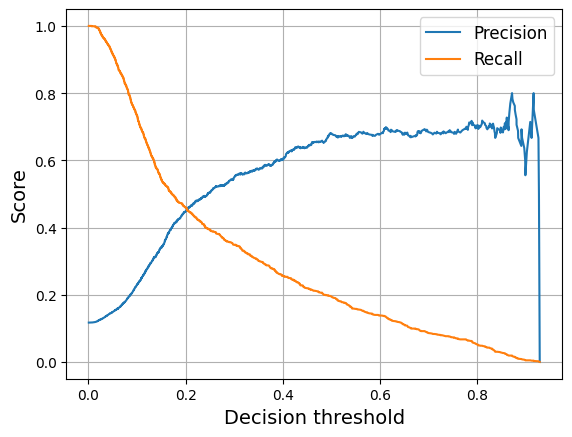

In [ ]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    clean_val_proba
)

plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")

plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

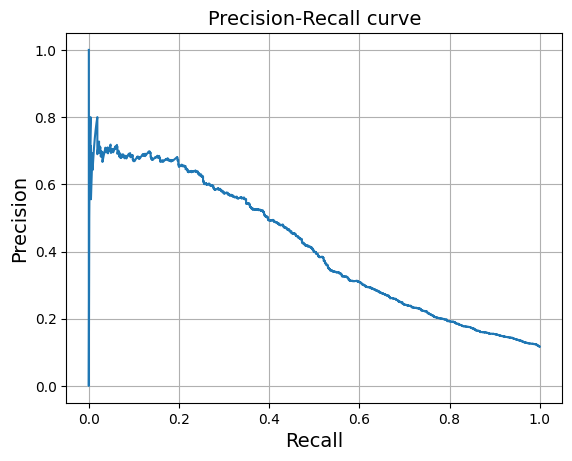

In [ ]:
plt.plot(recalls, precisions)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve")
plt.grid()
plt.show()

여러 임곗값을 직접 비교한다. 필요하면 후보 값을 수정하거나 추가한다.

In [ ]:
threshold_candidates = [
    0.10, 0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50, 0.60
]

threshold_rows = []

for threshold in threshold_candidates:
    scores = classification_scores(
        y_val,
        clean_val_proba,
        threshold
    )

    pred = (
        clean_val_proba >= threshold
    ).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": scores["Accuracy"],
        "Precision": scores["Precision"],
        "Recall": scores["Recall"],
        "Predicted positive rate": pred.mean(),
        "FP": scores["FP"],
        "FN": scores["FN"]
    })

threshold_results = pd.DataFrame(threshold_rows)
threshold_results

,Threshold,Accuracy,Precision,Recall,Predicted positive rate,FP,FN
0,0.10,0.682150,0.230244,0.732514,0.372263,2591,283
1,0.15,0.823712,0.340855,0.542533,0.186242,1110,484
2,0.20,0.870714,0.448753,0.459357,0.119774,597,572
3,0.25,0.883875,0.504854,0.393195,0.091130,408,642
4,0.30,0.890400,0.549925,0.348771,0.074209,302,689
5,0.35,0.892059,0.574007,0.300567,0.061270,236,740
6,0.40,0.893276,0.603563,0.256144,0.049657,178,787
7,0.45,0.894271,0.640884,0.219282,0.040035,130,826
8,0.50,0.895045,0.679868,0.194707,0.033510,97,852
9,0.60,0.891506,0.679070,0.137996,0.023778,69,912


### ROC 곡선과 AUC를 확인한다

ROC-AUC는 특정 임곗값 하나가 아니라 여러 임곗값에서의 구분 능력을 요약한다.

임곗값 선택에는 정밀도와 재현율을 함께 사용한다.

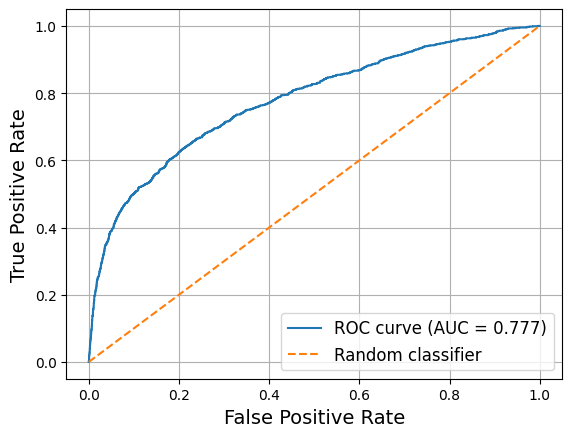

ROC-AUC: 0.7774801730114294


In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, roc_thresholds = roc_curve(
    y_val,
    clean_val_proba
)

roc_auc = roc_auc_score(
    y_val,
    clean_val_proba
)

plt.plot(
    fpr,
    tpr,
    label=f"ROC curve (AUC = {roc_auc:.3f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC:", roc_auc)

### 프로젝트 기록 ⑤ — 결정 임곗값 선택

먼저 어떤 오류가 더 중요한지 생각한다.

- **FP**: 가입할 것이라고 예측했지만 실제로는 가입하지 않은 고객
- **FN**: 실제 가입 고객인데 모델이 가입하지 않을 것으로 예측한 경우

다음을 기록한다.

- 이번 문제에서 더 줄이고 싶은 오류는 FP인가, FN인가? 그 이유는?: FN을 더 줄여야한다. FN은 실제 가입한 고객을 미가입할 것으로 잘못 예측하는 겅우이다. 이런 고객을 제외하면 잠재적인 가입 기회를 놓칠 수 있기 때문이다.
- 중요하게 볼 지표는 정밀도인가, 재현율인가?: 실제 가입 고객을 최대한 많이 찾아내는 것이 목적이므로 재현율을 더 중요하게 고려해야한다.
- 선택한 결정 임곗값: 0.20
- 선택한 임곗값에서의 정밀도: 약 45.94%
- 선택한 임곗값에서의 재현율: 약 44.88%
- **임곗값 선택 근거를 3~5문장으로 설명한다.** : 재현율을 높이고 싶다는 목적과 FP증가를 억제해야 한다는 현실적인 문제를 함께 생각하여 적절한 임계값으로 0.20을 선택하였다. 많은 가입 고객을 발견하기 위해 재현율을 지나치게 높였다간 불필요한 연락을 너무 많이 해야하는 겨우가 생기게 되어 재현율과 정밀도를 적절히 조절하여 임계값을 설정했다.

### AI 체크포인트 ② — 임곗값 선택 검토

`threshold_results`, Precision–Recall 곡선과 자신의 선택 근거를 AI에게 보여 주고 검토를 요청해도 된다.

직접 확인할 점은 다음과 같다.

- 정확도만으로 임곗값을 정하지 않았는가?
- FP와 FN의 의미를 바꾸어 해석하지 않았는가?
- 검증 데이터만 사용해 임곗값을 선택했는가?
- 테스트 결과를 본 뒤 임곗값을 바꾸지 않았는가?

### 최종 임곗값을 확정한다

아래 값을 자신의 선택에 맞게 수정한다.

**최종 테스트 결과를 보기 전에 값을 확정한다.**

In [ ]:
chosen_threshold = 0.50  # TODO: 검증 결과와 자신의 판단에 따라 수정

assert 0 < chosen_threshold < 1

print("최종 결정 임곗값:", chosen_threshold)

### 선택 과제 — `education`을 ordinal로 처리할까?

기본 분석에서는 `education`을 원-핫 인코딩했다.

`primary < secondary < tertiary`라는 순서는 생각할 수 있지만, 이를 `1, 2, 3`으로 바꾸면 로지스틱 회귀는 **각 단계 사이의 효과가 일정하다는 추가 가정**을 하게 된다.

관심이 있다면 다음을 비교해 본다.

- 기본 모델: `education` 원-핫 인코딩
- 비교 모델: `education` ordinal 인코딩

`unknown`을 어떤 방식으로 처리할지도 먼저 정하고 그 이유를 기록한다.

> 이 비교는 선택 과제이며 최종 모델에는 기본 one-hot 모델을 사용해도 된다.

### 2단계 마무리 체크

다음을 설명할 수 있는지 확인한다.

- 기준선 모델의 역할
- 정확도만으로 판단하면 안 되는 이유
- `duration` 누수 모델의 성능이 좋아도 사용할 수 없는 이유
- 정밀도와 재현율의 차이
- 결정 임곗값을 바꾸면 FP와 FN이 달라지는 이유
- 검증 데이터에서 임곗값을 선택해야 하는 이유

## 3단계 — 최종 평가, 오류 분석, 해석과 판단

### 누수가 없는 모델을 개발 데이터 전체로 다시 학습한다

모델과 결정 임곗값 선택이 끝났으므로, 누수가 없는 로지스틱 회귀를 **개발 데이터 전체**로 다시 학습한다.

이후 처음으로 최종 테스트셋에서 성능을 확인한다.

In [ ]:
X_dev_all = dev_df[feature_cols]
y_dev_all = dev_df[target]

X_test = test_df[feature_cols]
y_test = test_df[target]

final_model = make_pipeline(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

final_model.fit(
    X_dev_all,
    y_dev_all
)

test_proba = final_model.predict_proba(
    X_test
)[:, 1]

test_scores = classification_scores(
    y_test,
    test_proba,
    threshold=chosen_threshold
)

pd.Series(test_scores, name="Final test")

### 프로젝트 기록 ⑥ — 최종 성능 해석

지표를 숫자 그대로 옮기지 말고 의미를 설명한다.

- **Accuracy 해석**:
- **Precision 해석**:
- **Recall 해석**:
- **ROC-AUC 해석**:
- **FP와 FN의 수를 실제 마케팅 상황에서 어떻게 해석할 수 있는가?**:
- 검증 결과와 최종 테스트 결과는 얼마나 비슷하거나 달랐는가?:

### 최종 혼동 행렬을 확인한다

선택한 임곗값에서 어떤 종류의 오류가 발생했는지 확인한다.

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

test_pred = (
    test_proba >= chosen_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No", "Yes"]
)

plt.show()

### FP와 FN을 따로 살펴본다

테스트 결과에 예측 확률과 오류 유형을 추가한다.

In [ ]:
test_results = test_df.copy()

test_results["predicted_probability"] = test_proba
test_results["predicted"] = test_pred

test_results["error_type"] = np.select(
    [
        (test_results["y"] == 1) & (test_results["predicted"] == 1),
        (test_results["y"] == 0) & (test_results["predicted"] == 0),
        (test_results["y"] == 0) & (test_results["predicted"] == 1),
        (test_results["y"] == 1) & (test_results["predicted"] == 0),
    ],
    [
        "TP",
        "TN",
        "FP",
        "FN"
    ],
    default="?"
)

test_results["error_type"].value_counts()

### 한 조건을 선택해 오류 패턴을 확인한다

`education`, `job`, `housing`, `loan`, `poutcome` 중 하나를 선택한다.

집단별 오분류 비율이 크게 다른지 확인하고, **표본 수가 작은 집단의 비율은 조심해서 해석한다.**

In [ ]:
analysis_col = "education"  # TODO: 필요하면 다른 범주형 변수로 변경

error_by_group = pd.crosstab(
    test_results[analysis_col],
    test_results["error_type"],
    normalize="index"
)

group_counts = test_results[analysis_col].value_counts()

error_by_group = (
    error_by_group
    .join(group_counts.rename("count"))
    .sort_values("count", ascending=False)
)

error_by_group

### 오류 사례를 직접 확인한다

모델이 높은 확률로 가입을 예측했지만 실제로 가입하지 않은 FP와, 낮은 확률을 주었지만 실제로 가입한 FN을 살펴본다.

In [ ]:
fp_examples = (
    test_results.loc[
        test_results["error_type"] == "FP"
    ]
    .sort_values(
        "predicted_probability",
        ascending=False
    )
    .head(10)
)

fn_examples = (
    test_results.loc[
        test_results["error_type"] == "FN"
    ]
    .sort_values(
        "predicted_probability",
        ascending=True
    )
    .head(10)
)

print("False Positives")
display(fp_examples)

print("False Negatives")
display(fn_examples)

### 오류 분석 기록

다음을 기록한다.

- 선택한 집단에서 FP 또는 FN 비율이 눈에 띄게 높은 경우가 있는가?
- 표본 수가 충분한가?
- FP 사례에서 반복해서 보이는 특성이 있는가?
- FN 사례에서 반복해서 보이는 특성이 있는가?
- 전체 정밀도·재현율만으로는 놓칠 수 있는 점은 무엇인가?

> 관찰된 패턴만으로 오류의 원인을 단정하지 않는다.

### 예측 관계와 인과관계를 구분한다

예를 들어 특정 직업이나 교육 수준이 가입 여부 예측에 유용하다고 해서,

> “그 특성이 정기예금 가입을 **원인으로 만들어낸다**”

고 말할 수는 없다.

이번 프로젝트는 관찰 데이터에 기반한 **예측 문제**이며, 변수 간의 인과관계를 확인하는 분석이 아니다.

### 실제 활용에서는 추가 판단이 필요하다

모델이 좋은 성능을 보이더라도 바로 실제 고객 선정에 사용하면 안 된다.

다음을 추가로 검토해야 한다.

- 다른 시기와 다른 캠페인에서도 성능이 유지되는가?
- 고객 구성이나 마케팅 방식이 바뀌면 성능이 달라지는가?
- 선택한 임곗값이 실제 연락 비용과 목표에 맞는가?
- 특정 고객 집단에서 오류가 지나치게 크지 않은가?
- 개인정보, 공정성, 관련 규정을 고려했는가?

### AI 체크포인트 ③ — 결과 해석 검토

최종 결과와 오류 분석을 AI에게 보여 주고 결론 초안을 검토받아도 된다.

다음은 직접 확인한다.

- 테스트 결과를 보고 임곗값을 다시 바꾸지 않았는가?
- 높은 ROC-AUC를 모든 상황에서 좋은 성능이라고 단정하지 않았는가?
- 예측 관계를 인과관계로 바꾸지 않았는가?
- 특정 집단의 작은 표본에서 나타난 차이를 과도하게 일반화하지 않았는가?
- `duration`을 다시 실제 입력 변수처럼 해석하지 않았는가?

**수정하거나 받아들이지 않은 AI의 제안과 그 이유**

> 작성:

### 최종 결론을 작성한다

다음 내용을 포함한다.

- **분석 질문에 대한 답**
- **`duration`을 제외한 이유**
- **로지스틱 회귀와 기준선의 차이**
- **선택한 결정 임곗값과 선택 근거**
- **정밀도·재현율·ROC-AUC의 의미**
- **FP와 FN 중 더 중요하게 판단한 오류**
- **오류 분석에서 발견한 점**
- **실제 활용 가능성**
- **분석의 한계 두 가지 이상**
- **다음 분석에서 추가할 정보 또는 방법**

### 프로젝트 최종 제출 전 확인

- [ ] 타깃, 양성 클래스와 예측 시점을 설명했다.
- [ ] 최종 테스트셋을 모델·임곗값 선택에 사용하지 않았다.
- [ ] `duration`이 데이터 누수인 이유를 설명했다.
- [ ] 범주형 변수에 원-핫 인코딩을 적용했다.
- [ ] 기준선과 로지스틱 회귀를 비교했다.
- [ ] 정확도, 정밀도, 재현율, ROC-AUC를 해석했다.
- [ ] 결정 임곗값을 검증 데이터에서 선택하고 근거를 적었다.
- [ ] 최종 테스트셋에서 선택한 임곗값을 그대로 사용했다.
- [ ] FP와 FN을 실제 문제의 관점에서 해석했다.
- [ ] 오류 분석과 분석의 한계를 적었다.
- [ ] AI의 제안을 검토한 근거를 남겼다.

### 평가 기준

| 영역 | 배점 | 확인할 내용 |
|---|---:|---|
| 문제와 데이터 이해 | 4 | 타깃·양성 클래스·예측 시점·데이터 누수를 적절히 설명했는가? |
| 분석 방법 | 4 | 데이터 분할·전처리·기준선·로지스틱 회귀의 절차가 타당한가? |
| 평가와 임곗값 판단 | 5 | 정확도·정밀도·재현율·ROC-AUC를 구분하고 임곗값 선택에 자신의 근거가 있는가? |
| 결과 해석 | 4 | 최종 성능과 FP·FN 및 조건별 오류를 현실의 언어로 정확히 해석했는가? |
| 검증과 한계 | 3 | 테스트셋 보존, AI 결과 검토, 일반화와 한계를 적절히 다루었는가? |
| **합계** | **20** | |